Computing recurrence intervals with IMERG time series at Hunt, Texas
July 2025 Flood Event

Extreme value analysis (EVA) method: Peaks Over Threshold (POT)

Jacob R. Schaperow - jacob.r.schaperow@nasa.gov
Andrew M. Fisher - andrew.m.fisher@nasa.gov
Ariana L. McDermott - ariana.m.louise@nasa.gov

In [30]:
# Import packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyextremes import EVA

In [31]:
# Import time series data

df = pd.read_csv('./Data/hunt_texas_IMERG_daily.txt')
df.columns = ['date','precip_mm']
print(df.head())

ds_series = df.set_index('date')['precip_mm']
print(ds_series.head())

ds_series.index = pd.to_datetime(ds_series.index)

         date  precip_mm
0  1998-01-01      0.000
1  1998-01-02      0.000
2  1998-01-03      0.085
3  1998-01-04      0.000
4  1998-01-05      0.000
date
1998-01-01    0.000
1998-01-02    0.000
1998-01-03    0.085
1998-01-04    0.000
1998-01-05    0.000
Name: precip_mm, dtype: float64


In [32]:
# Clean data by removing zeros

df_noz = ds_series[ds_series>0]
print(df_noz.head())
print(len(df_noz))
print(len(ds_series))

date
1998-01-03     0.085
1998-01-06    27.195
1998-01-07     0.755
1998-01-20     0.260
1998-01-22     1.305
Name: precip_mm, dtype: float64
3221
10135


date
1998-03-16     76.870
1998-08-23     51.060
1998-10-06    107.755
1999-06-13     58.355
2000-10-23     68.595
Name: precip_mm, dtype: float64


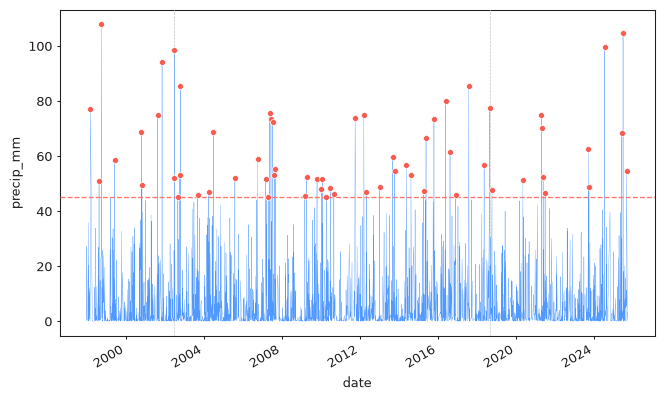

In [33]:
# Creating a model for the time series data using the Peaks Over Threshold (POT) method

model = EVA(df_noz)
model.get_extremes("POT", threshold=45, r="24h")
print(model.extremes.head())
model.plot_extremes(show_clusters=True)
plt.show()

In [34]:
# Estimating return periods - POT method

from pyextremes import get_extremes, get_return_periods

extremes = get_extremes(
    ts=df_noz,
    method="POT",
    threshold=45,
    r="24h",
)
return_periods = get_return_periods(
    ts=df_noz,
    extremes=extremes,
    extremes_method="POT",
    extremes_type="high",
    return_period_size="24h",
    plotting_position="weibull",
)
return_periods.sort_values("return period", ascending=False).head()

,precip_mm,exceedance probability,return period
date,,,
1998-10-06,107.755,0.015873,10295.419355
2025-07-04,104.625,0.031746,5147.709677
2024-07-23,99.590,0.047619,3431.806452
2002-07-04,98.555,0.063492,2573.854839
2001-11-15,94.000,0.079365,2059.083871


                           Univariate Extreme Value Analysis                            
                                      Source Data                                       
----------------------------------------------------------------------------------------
Data label:                     precip_mm      Size:                               3,221
Start:                       January 1998      End:                       September 2025
                                     Extreme Values                                     
----------------------------------------------------------------------------------------
Count:                                 62      Extraction method:                    POT
Type:                                high      Threshold:                             45
                                         Model                                          
----------------------------------------------------------------------------------------
Model:               

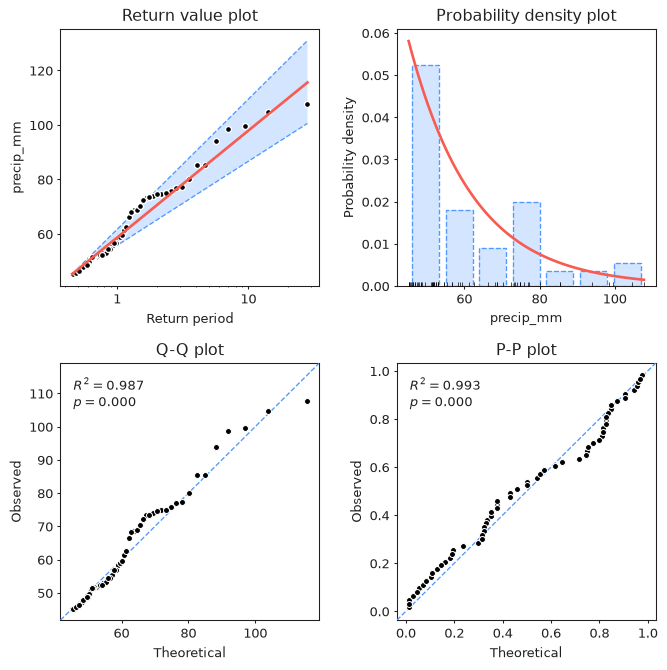

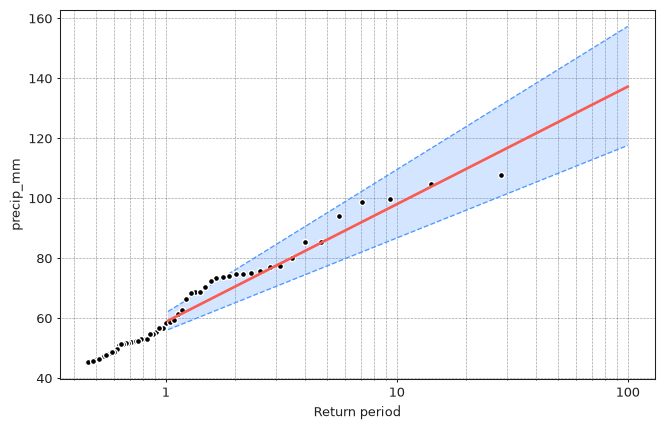

In [35]:
# Fit a model to the extreme values

model.fit_model() # default fitting method is MLE - Maximum Likelihood Estimate 
print(model)

model.plot_diagnostic(alpha=0.95)

model.plot_return_values(
    return_period = np.logspace(0.01,2,100),
    alpha = 0.95
)
plt.show()

In [37]:
# Estimate return values

summary = model.get_summary(
    return_period=[1, 2, 5, 10, 25, 45, 50, 100],
    alpha=0.95,
    n_samples=1000,
)
print(summary)

               return value    lower ci    upper ci
return period                                      
1.0               58.703698   55.772817   61.858326
2.0               70.514423   65.057521   76.387910
5.0               86.127352   77.331231   95.594977
10.0              97.938077   86.615935  110.124562
25.0             113.551006   98.889646  129.331628
45.0             123.566464  106.763046  141.652671
50.0             125.361731  108.174349  143.861213
100.0            137.172456  117.459053  158.390798


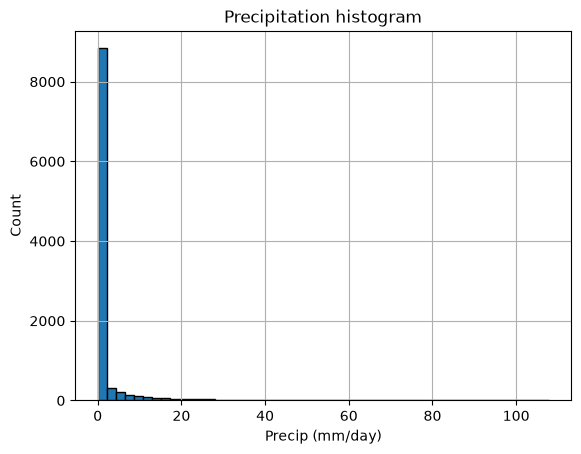

In [44]:
# Plot histogram (with zeros)

df['precip_mm'].hist(bins = 50, edgecolor='black')
plt.title('Precipitation histogram')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

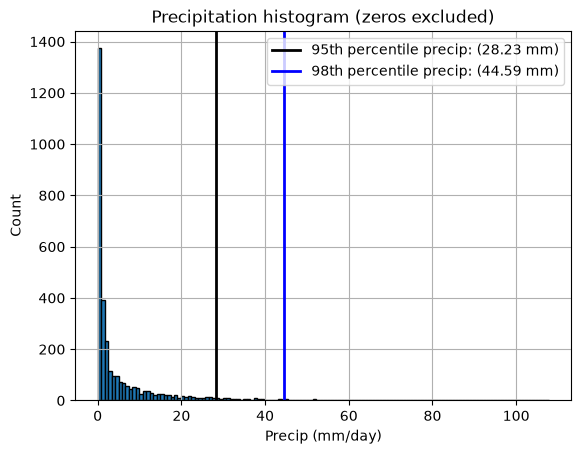

In [45]:
# Plot histogram (without zeros)

df_noz = df[df['precip_mm']>0]
p95 = np.percentile(df_noz['precip_mm'], 95) # calculate 95% precipitation
p98 = np.percentile(df_noz['precip_mm'], 98) # calculate 99% precipitation


df_noz['precip_mm'].hist(bins = "fd", edgecolor='black')
plt.axvline(x = p95, 
    color = "black", 
    linewidth = 2, 
    label=f"95th percentile precip: ({p95:.2f} mm)"
)
plt.axvline(x = p98, 
    color = "blue", 
    linewidth = 2, 
    label=f"98th percentile precip: ({p98:.2f} mm)"
)

plt.title('Precipitation histogram (zeros excluded)')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.legend()
plt.show()

161


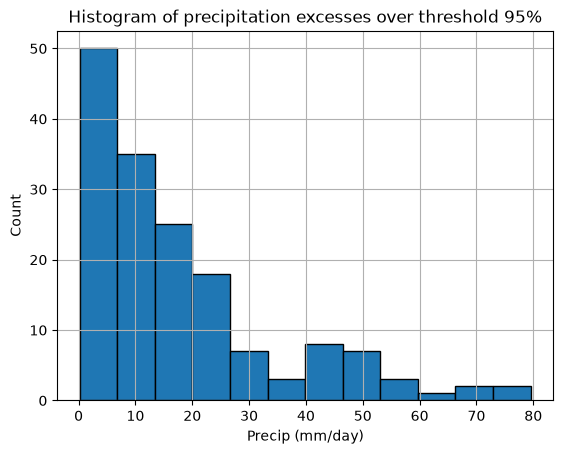

In [40]:
# Implement peak-over-threshold (POT) method

# Choosing threshold of p95 for peak-over-threshold method
threshold95 = p95 # this might be too low...

# Get precipitation data over the threshold value
df_peaks = df_noz[df_noz['precip_mm']>threshold95]
df_peaks.head()
print(len(df_peaks))

df_excesses = df_peaks['precip_mm'] - threshold95

# Plot histogram of extreme values
df_excesses.hist(bins = "fd", edgecolor = "black")
plt.title('Histogram of precipitation excesses over threshold 95%')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

# We should implement a check to remove consecutive peaks that are actually part of the same storm event
# For example, ensure there is at least one full day in between peaks
# This will help with independence, and satisfying the extreme value theorem, which requires i.i.d. random variables


65


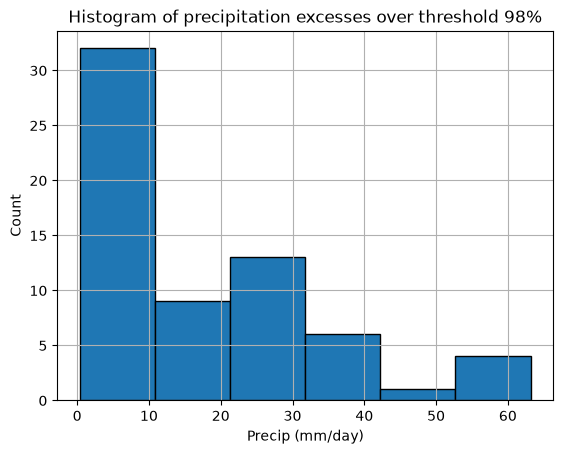

In [46]:
# Choosing threshold of p99 for peak-over-threshold method
threshold98 = p98 # this might be too low...

# Get precipitation data over the threshold value
df_peaks = df_noz[df_noz['precip_mm']>threshold98]
df_peaks.head()
print(len(df_peaks))

df_excesses = df_peaks['precip_mm'] - threshold98

# Plot histogram of extreme values
df_excesses.hist(bins = "fd", edgecolor = "black")
plt.title('Histogram of precipitation excesses over threshold 98%')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

In [ ]:
'''
from pyextremes import plot_mean_residual_life

plot_mean_residual_life(df_noz)
'''